# Import libraries

In [13]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import GofChisquarePower
from sklearn.cluster import KMeans
import sklearn.metrics as sil
from ratio import find_power_vals

# Import humans

In [14]:
chrom = 22

In [15]:
humans = pd.read_pickle('./data/phenotype/humans_maf_popstrat.pkl')

In [16]:
humans

,sample,sample.1,pop,super_pop,gender,dim1_maf_0.01_0,dim2_maf_0.01_0,pheno_maf_0.01_0,dim1_maf_0.01_1,dim2_maf_0.01_1,...,pheno_maf_0.38_6,dim1_maf_0.38_7,dim2_maf_0.38_7,pheno_maf_0.38_7,dim1_maf_0.38_8,dim2_maf_0.38_8,pheno_maf_0.38_8,dim1_maf_0.38_9,dim2_maf_0.38_9,pheno_maf_0.38_9
0,HG00096,HG00096,GBR,EUR,male,-0.333826,-0.040902,-0.375,-0.443677,-0.035165,...,0.798,1.161069,-1.495549,-0.334,-0.949972,1.813149,0.863,-1.171391,2.553751,1.382
1,HG00097,HG00097,GBR,EUR,female,-0.415651,-0.027549,-0.443,-0.446558,-0.046905,...,-1.951,0.775375,-1.270812,-0.495,1.337061,1.534934,2.872,-1.564318,0.682684,-0.882
2,HG00099,HG00099,GBR,EUR,female,-0.208906,-0.561815,-0.771,-0.446295,-0.045300,...,-0.305,-0.104672,0.065098,-0.040,1.284260,1.562281,2.847,-1.201526,0.876214,-0.325
3,HG00100,HG00100,GBR,EUR,female,-0.252399,-0.179090,-0.431,-0.446558,-0.046905,...,-1.274,0.524489,-1.341814,-0.817,1.590940,1.699035,3.290,-2.154419,0.918490,-1.236
4,HG00101,HG00101,GBR,EUR,male,-0.448655,-0.002134,-0.451,-0.446558,-0.046905,...,-1.597,1.043540,-1.507435,-0.464,3.186151,0.109423,3.296,-0.814364,-0.168550,-0.983
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female,-1.082979,1.045842,-0.037,-0.446558,-0.046905,...,0.524,-0.850039,0.270451,-0.580,0.878573,0.917069,1.796,0.617828,-0.473264,0.145
2500,NA21141,NA21141,GIH,SAS,female,-0.478558,-0.097333,-0.576,-0.446558,-0.046905,...,-0.352,-1.235123,0.222965,-1.012,2.338984,0.123233,2.462,0.148965,-0.619124,-0.470
2501,NA21142,NA21142,GIH,SAS,female,-0.469718,-0.023920,-0.494,-0.412680,-0.066426,...,0.751,-0.907650,0.232175,-0.675,-1.234109,1.443456,0.209,1.212882,0.247591,1.460
2502,NA21143,NA21143,GIH,SAS,female,-0.511315,0.026747,-0.485,-0.446558,-0.046905,...,-0.579,0.223853,-1.235748,-1.012,-0.798232,1.020149,0.222,2.321041,0.463230,2.784


# Import snps

In [17]:
os.listdir(f"./data/genotype/chrom_{chrom}")

['11_5_961_11_maf_0.32_0.38.pkl',
 '5_6_800_5_maf_0.067_0.091.pkl',
 '0_3_802_0_maf_0.01_0.016.pkl',
 '7_2_1200_7_maf_0.12_0.16.pkl',
 '1_8_800_1_maf_0.016_0.023.pkl',
 '4_7_800_4_maf_0.049_0.067.pkl',
 '5_8_800_5_maf_0.067_0.091.pkl',
 '0_0_815_0_maf_0.01_0.016.pkl',
 '10_6_800_10_maf_0.26_0.32.pkl',
 '1_6_1200_1_maf_0.016_0.023.pkl',
 '12_7_800_12_maf_0.38_0.45.pkl',
 '2_7_800_2_maf_0.023_0.035.pkl',
 '12_0_1200_12_maf_0.38_0.45.pkl',
 '6_9_972_6_maf_0.091_0.12.pkl',
 '6_4_1200_6_maf_0.091_0.12.pkl',
 '7_7_1135_7_maf_0.12_0.16.pkl',
 '7_0_1200_7_maf_0.12_0.16.pkl',
 '9_8_1076_9_maf_0.21_0.26.pkl',
 '0_7_800_0_maf_0.01_0.016.pkl',
 '7_9_800_7_maf_0.12_0.16.pkl',
 '7_1_800_7_maf_0.12_0.16.pkl',
 '8_3_800_8_maf_0.16_0.21.pkl',
 '5_2_1200_5_maf_0.067_0.091.pkl',
 '3_5_800_3_maf_0.035_0.049.pkl',
 '3_1_1200_3_maf_0.035_0.049.pkl',
 '5_0_1200_5_maf_0.067_0.091.pkl',
 '4_4_1009_4_maf_0.049_0.067.pkl',
 '11_3_1016_11_maf_0.32_0.38.pkl',
 '7_3_1189_7_maf_0.12_0.16.pkl',
 '2_9_800_2_maf_0.023_

In [18]:
wanted_maf = "0.12_0.16"

In [19]:
snps = [f for f in os.listdir(f"./data/genotype/chrom_{chrom}") if f.split("_maf_")[1].split('.pkl')[0] == wanted_maf]
for snp in snps:
    maf = snp.split("_maf_")[1].split('.pkl')[0]
    print(maf)
    path_snp = f"./data/genotype//chrom_{chrom}/{snp}"
    print(path_snp)
    geno = pd.read_pickle(path_snp)

0.12_0.16
./data/genotype//chrom_22/7_2_1200_7_maf_0.12_0.16.pkl
0.12_0.16
./data/genotype//chrom_22/7_7_1135_7_maf_0.12_0.16.pkl
0.12_0.16
./data/genotype//chrom_22/7_0_1200_7_maf_0.12_0.16.pkl
0.12_0.16
./data/genotype//chrom_22/7_9_800_7_maf_0.12_0.16.pkl
0.12_0.16
./data/genotype//chrom_22/7_1_800_7_maf_0.12_0.16.pkl
0.12_0.16
./data/genotype//chrom_22/7_3_1189_7_maf_0.12_0.16.pkl
0.12_0.16
./data/genotype//chrom_22/7_6_1142_7_maf_0.12_0.16.pkl
0.12_0.16
./data/genotype//chrom_22/7_4_800_7_maf_0.12_0.16.pkl
0.12_0.16
./data/genotype//chrom_22/7_5_800_7_maf_0.12_0.16.pkl
0.12_0.16
./data/genotype//chrom_22/7_8_934_7_maf_0.12_0.16.pkl


In [20]:
snp_num = 1
geno[geno.columns[snp_num]].value_counts()
num_maj = geno[geno.columns[snp_num]].value_counts()[1]
num_het = geno[geno.columns[snp_num]].value_counts()[0]
try:
    num_min = geno[geno.columns[snp_num]].value_counts()[-1]
except Exception as e:
    num_min = 0
total_humans = num_maj + num_het + num_min
maf = (num_min*2 + num_het)/(total_humans*2)
maf

0.15914536741214058

In [21]:
min_power = 80
[a, b, c] = find_power_vals(min_power)
ratio = a*maf**2 + b*maf + c

true_mean = 0
true_effect = 5
true_sd = true_effect*ratio

mean_min = true_mean
mean_het = true_mean
mean_maj = true_mean
sigma_min = true_sd
sigma_het = true_sd
sigma_maj = true_sd

iteration = 5000

In [22]:
true_sd

51.054419883773505

In [23]:
humans

,sample,sample.1,pop,super_pop,gender,dim1_maf_0.01_0,dim2_maf_0.01_0,pheno_maf_0.01_0,dim1_maf_0.01_1,dim2_maf_0.01_1,...,pheno_maf_0.38_6,dim1_maf_0.38_7,dim2_maf_0.38_7,pheno_maf_0.38_7,dim1_maf_0.38_8,dim2_maf_0.38_8,pheno_maf_0.38_8,dim1_maf_0.38_9,dim2_maf_0.38_9,pheno_maf_0.38_9
0,HG00096,HG00096,GBR,EUR,male,-0.333826,-0.040902,-0.375,-0.443677,-0.035165,...,0.798,1.161069,-1.495549,-0.334,-0.949972,1.813149,0.863,-1.171391,2.553751,1.382
1,HG00097,HG00097,GBR,EUR,female,-0.415651,-0.027549,-0.443,-0.446558,-0.046905,...,-1.951,0.775375,-1.270812,-0.495,1.337061,1.534934,2.872,-1.564318,0.682684,-0.882
2,HG00099,HG00099,GBR,EUR,female,-0.208906,-0.561815,-0.771,-0.446295,-0.045300,...,-0.305,-0.104672,0.065098,-0.040,1.284260,1.562281,2.847,-1.201526,0.876214,-0.325
3,HG00100,HG00100,GBR,EUR,female,-0.252399,-0.179090,-0.431,-0.446558,-0.046905,...,-1.274,0.524489,-1.341814,-0.817,1.590940,1.699035,3.290,-2.154419,0.918490,-1.236
4,HG00101,HG00101,GBR,EUR,male,-0.448655,-0.002134,-0.451,-0.446558,-0.046905,...,-1.597,1.043540,-1.507435,-0.464,3.186151,0.109423,3.296,-0.814364,-0.168550,-0.983
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female,-1.082979,1.045842,-0.037,-0.446558,-0.046905,...,0.524,-0.850039,0.270451,-0.580,0.878573,0.917069,1.796,0.617828,-0.473264,0.145
2500,NA21141,NA21141,GIH,SAS,female,-0.478558,-0.097333,-0.576,-0.446558,-0.046905,...,-0.352,-1.235123,0.222965,-1.012,2.338984,0.123233,2.462,0.148965,-0.619124,-0.470
2501,NA21142,NA21142,GIH,SAS,female,-0.469718,-0.023920,-0.494,-0.412680,-0.066426,...,0.751,-0.907650,0.232175,-0.675,-1.234109,1.443456,0.209,1.212882,0.247591,1.460
2502,NA21143,NA21143,GIH,SAS,female,-0.511315,0.026747,-0.485,-0.446558,-0.046905,...,-0.579,0.223853,-1.235748,-1.012,-0.798232,1.020149,0.222,2.321041,0.463230,2.784


In [24]:
multiplicator = 1

In [25]:
maf_pop = 0.023
nr_segment = 2
humans[f"pheno_maf_{maf_pop}_{nr_segment}"] = humans[f"pheno_maf_{maf_pop}_{nr_segment}"]*multiplicator
pheno_pop = humans[f"pheno_maf_{maf_pop}_{nr_segment}"]

In [26]:
pheno_pop = []
for var in list(humans[f"pheno_maf_{maf_pop}_{nr_segment}"]):
    pheno_pop.append(np.random.normal(var, true_sd, 1)[0])

In [27]:
humans['pheno_pop'] = pheno_pop
pheno_pop = humans['pheno_pop']

/tmp/ipykernel_758/2369045904.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  humans['pheno_pop'] = pheno_pop


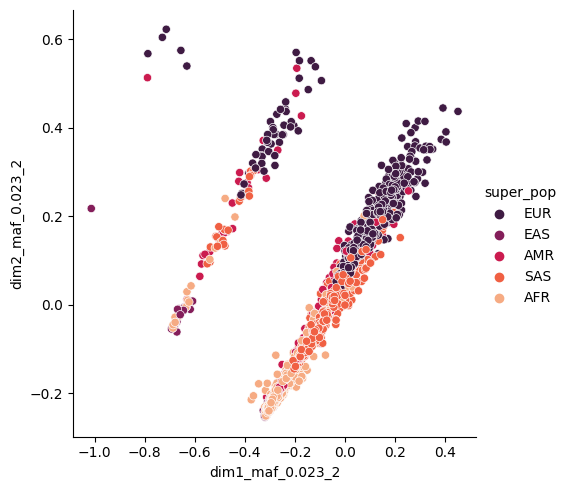

In [28]:
g = sns.relplot(
    data=humans,
    x=f"dim1_maf_{maf_pop}_{nr_segment}", y=f"dim2_maf_{maf_pop}_{nr_segment}",
    hue="super_pop",
    palette='rocket', sizes=(10, 200))
plt.show()

/tmp/ipykernel_758/2481994055.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  humans[f"causal"] = geno[geno.columns[snp_num]]


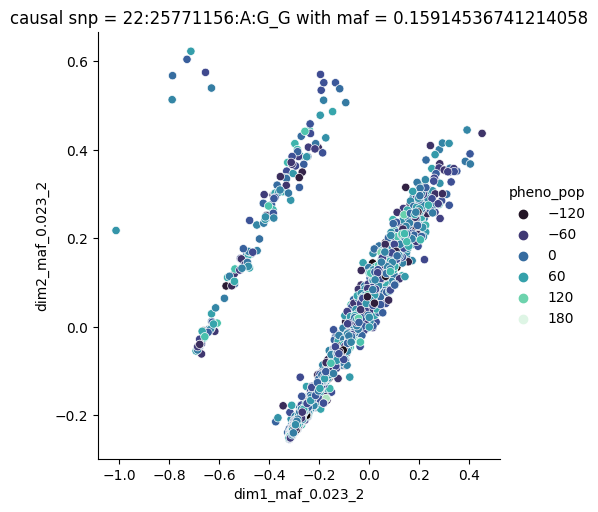

In [29]:
humans[f"causal"] = geno[geno.columns[snp_num]]
g = sns.relplot(
    data=humans,
    x=f"dim1_maf_{maf_pop}_{nr_segment}", y=f"dim2_maf_{maf_pop}_{nr_segment}",
    hue=f"pheno_pop",
    palette='mako', sizes=(10, 200)).set(title=f"causal snp = {geno.columns[snp_num]} with maf = {maf}")
plt.show()

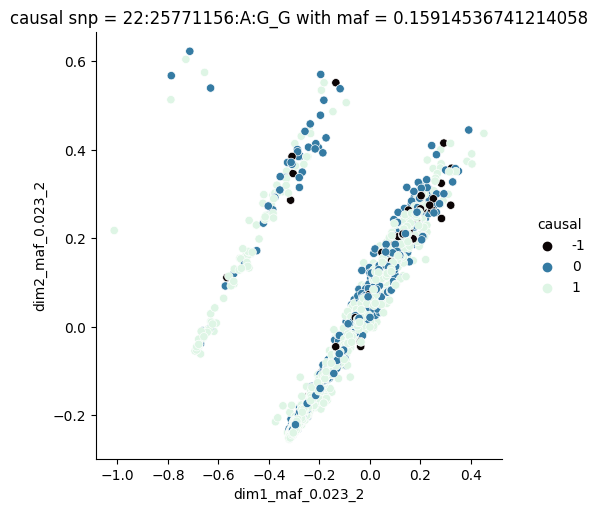

In [30]:
humans[f"causal"] = geno[geno.columns[snp_num]]
g = sns.relplot(
    data=humans,
    x=f"dim1_maf_{maf_pop}_{nr_segment}", y=f"dim2_maf_{maf_pop}_{nr_segment}",
    hue=f"causal",
    palette='mako', sizes=(10, 200)).set(title=f"causal snp = {geno.columns[snp_num]} with maf = {maf}")
plt.show()

In [31]:
humans_maj = humans[humans['causal']== 1]
humans_het = humans[humans['causal']== 0]
humans_min = humans[humans['causal']== -1]
#df.loc[['viper', 'sidewinder'], ['shield']] = 50

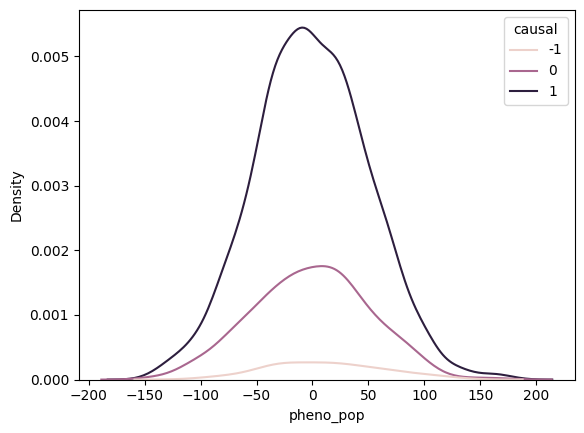

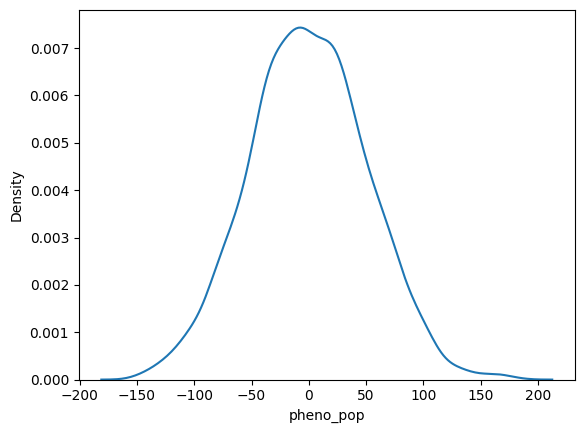

In [32]:
g1 = sns.kdeplot(data=humans, x=f"pheno_pop", hue="causal")
X_maj = g1.get_lines()[0].get_data()[0]
X_het = g1.get_lines()[1].get_data()[0]
X_min = g1.get_lines()[2].get_data()[0]
y_maj = g1.get_lines()[0].get_data()[1]
y_het = g1.get_lines()[1].get_data()[1]
y_min = g1.get_lines()[2].get_data()[1]
plt.show()
g2 = sns.kdeplot(data=humans, x=f"pheno_pop")
X_tot = g2.get_lines()[0].get_data()[0]
y_tot = g2.get_lines()[0].get_data()[1]
y_maj_diff = y_maj/y_tot
y_het_diff = y_het/y_tot
y_min_diff = y_min/y_tot
plt.show()

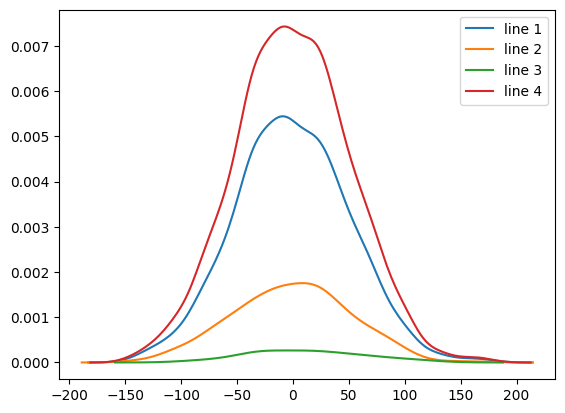

In [33]:
# plot lines
plt.plot(X_maj, y_maj, label = "line 1")
plt.plot(X_het, y_het, label = "line 2")
plt.plot(X_min, y_min, label = "line 3")
plt.plot(X_tot, y_tot, label = "line 4")
plt.legend()
plt.show()

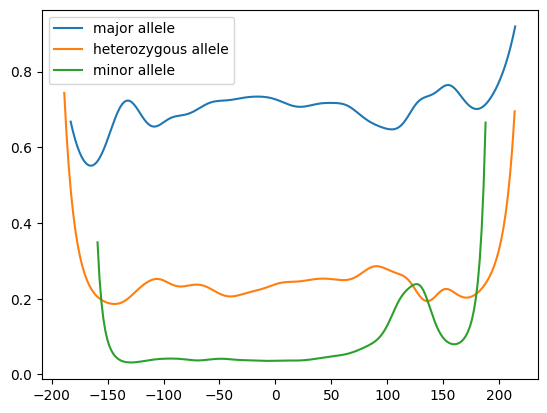

In [34]:
# plot lines
plt.plot(X_maj, y_maj_diff, label = "major allele")
plt.plot(X_het, y_het_diff, label = "heterozygous allele")
plt.plot(X_min, y_min_diff, label = "minor allele")
plt.legend()
plt.show()

## Finding betha_pop manually

In [35]:
humans['pheno'] = humans[[f"pheno_pop"]]

0.0006593320729415542


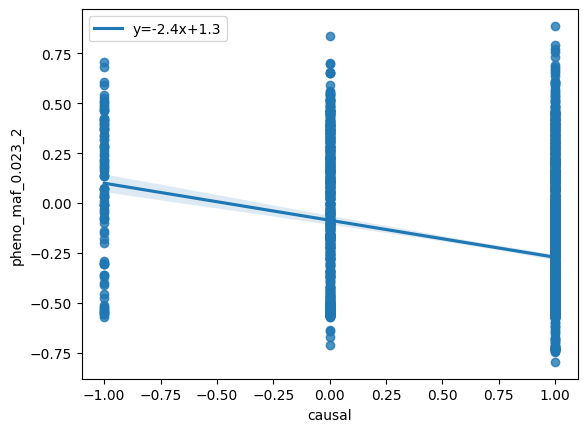

In [36]:
X = humans[['causal']]
y = humans[['pheno']]
reg = LinearRegression().fit(X, y)
print(reg.score(X, y))
estimated_effect = reg.coef_[0][0]
estimated_intercept = reg.intercept_[0]
def find_lin_reg(X):
    y = reg.coef_[0][0]*X + reg.intercept_[0]
    return y
# use line_kws to set line label for legend
ax = sns.regplot(x="causal", y=f"pheno_maf_{maf_pop}_{nr_segment}", data=humans, 
 line_kws={'label':"y={0:.1f}x+{1:.1f}".format(estimated_effect,estimated_intercept)})

# plot legend
ax.legend()

plt.show()

In [37]:
X

,causal
0,0
1,0
2,1
3,1
4,1
...,...
2499,0
2500,1
2501,1
2502,-1


In [38]:
N = len(X)
p = len(X.columns) + 1

X_with_intercept = np.empty(shape=(N, p), dtype=float)
X_with_intercept[:, 0] = 1
X_with_intercept[:, 1:p] = X.values

params = np.append(reg.intercept_,reg.coef_)
predictions = reg.predict(X)
new_y = (y-predictions)**2
newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['causal'])))
MSE = (sum(list(new_y['pheno'])))/(len(newX)-len(newX.columns))

var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
sd_b = np.sqrt(var_b)
ts_b = params/ sd_b

print(f"var = {var_b}")
print(f"sd = {sd_b}")
print(f"t_square = {ts_b}")
p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]

residuals = y - predictions
residual_sum_of_squares = residuals.T @ residuals
sigma_squared_hat = residual_sum_of_squares['pheno'].pheno / (N - p)
var_beta_hat = np.linalg.inv(X_with_intercept.T @ X_with_intercept) * sigma_squared_hat
SE = []
for p_ in range(p):
    standard_error = var_beta_hat[p_, p_] ** 0.5
    SE.append(standard_error)
    print(f"SE(beta_hat[{p_}]): {standard_error}")

sd_b = np.round(sd_b,3)
ts_b = np.round(ts_b,3)
params = np.round(params,4)

distribution_nul = np.random.normal(0, SE[1], 5000)
distribution_alt = np.random.normal(estimated_effect, SE[1], 5000)

dis_only_alt = pd.DataFrame(data={"Z": list(distribution_alt)})
dis_only_alt['Z2'] = (dis_only_alt['Z']/SE[1])**2
cuttof = stats.chi2.ppf(0.8, df=1)
omega = 0
for val in list(dis_only_alt['Z2']):
    if val > cuttof:
        omega += 1
    else:
        pass
power = omega/len(list(dis_only_alt['Z2']))
print(round(power*100,8))

var = [2.70138569 3.56201673]
sd = [1.64358927 1.88733058]
t_square = [ 0.79943379 -1.28481019]
SE(beta_hat[0]): 1.6435892707743869
SE(beta_hat[1]): 1.8873305831260758
50.04


In [39]:
cuttof

1.642374415149818

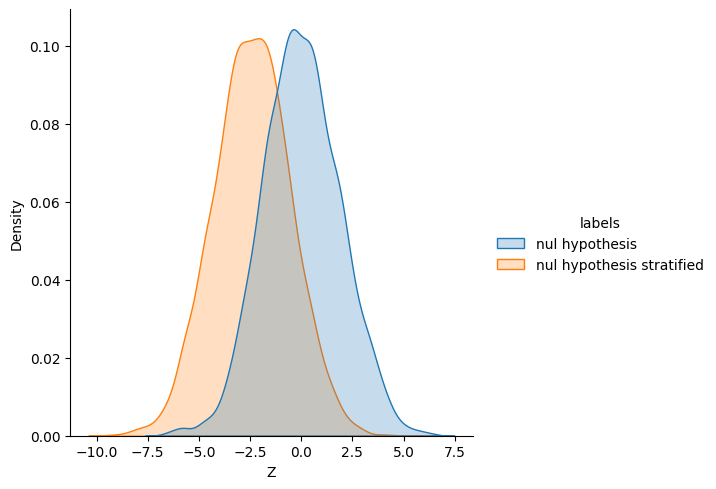

In [58]:
labels = ['nul hypothesis']*len(distribution_nul) + ['nul hypothesis stratified'] * len(distribution_alt)
dis = pd.DataFrame(data={"Z": list(distribution_nul)+list(distribution_alt), 'labels': labels})
sns.displot(dis, x="Z", hue='labels',kind="kde",fill=True)
plt.show()

## Nul no strat

In [41]:
estimated_effect_nul = []
estimated_intercept_nul = []
SE_nul = []
p_nul = []

i = 0
for i in range(iteration):
    mean_min = true_mean
    mean_het = true_mean
    mean_maj = true_mean
    sigma_min = true_sd
    sigma_het = true_sd
    sigma_maj = true_sd
    pheno = []
    for var in list(geno[geno.columns[snp_num]]):
        if var == 1:
            pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
        elif var == 0:
            pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
        else:
            pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
    df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[snp_num]]), "pheno_null": pheno})

    X = df_pheno[['geno']]
    y = df_pheno[['pheno_null']]
    reg = LinearRegression().fit(X, y)
    estimated_effect_nul.append(reg.coef_[0][0])
    estimated_intercept_nul.append(reg.intercept_[0])
    
    # Calculating p values and standard error
    N = len(X)
    p = len(X.columns) + 1
    X_with_intercept = np.empty(shape=(N, p), dtype=float)
    X_with_intercept[:, 0] = 1
    X_with_intercept[:, 1:p] = X.values
    
    params = np.append(reg.intercept_,reg.coef_)
    predictions = reg.predict(X)
    new_y = (y-predictions)**2
    newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
    MSE = (sum(list(new_y['pheno_null'])))/(len(newX)-len(newX.columns))
    
    var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
    

    sd_b = np.sqrt(var_b)
    ts_b = params/ sd_b
    
    p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]
    
    SE_nul.append(sd_b[1])
    p_nul.append(p_values[1])

## Alt no strat

In [42]:
estimated_effect_alt = []
estimated_intercept_alt = []
SE_alt = []
p_alt = []

for i in range(iteration):
    mean_min = true_mean - true_effect
    mean_het = true_mean
    mean_maj = true_mean + true_effect
    sigma_min = true_sd
    sigma_het = true_sd
    sigma_maj = true_sd
    pheno = []
    for var in list(geno[geno.columns[snp_num]]):
        if var == 1:
            pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
        elif var == 0:
            pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
        else:
            pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
    df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[snp_num]]), "pheno": pheno})

    X = df_pheno[['geno']]
    y = df_pheno[['pheno']]
    reg = LinearRegression().fit(X, y)
    estimated_effect_alt.append(reg.coef_[0][0])
    estimated_intercept_alt.append(reg.intercept_[0])
    
    # Calculating p values and standard error
    N = len(X)
    p = len(X.columns) + 1
    X_with_intercept = np.empty(shape=(N, p), dtype=float)
    X_with_intercept[:, 0] = 1
    X_with_intercept[:, 1:p] = X.values
    
    params = np.append(reg.intercept_,reg.coef_)
    predictions = reg.predict(X)
    new_y = (y-predictions)**2
    newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
    MSE = (sum(list(new_y['pheno'])))/(len(newX)-len(newX.columns))
    
    var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
    sd_b = np.sqrt(var_b)
    ts_b = params/ sd_b
    
    p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]
    SE_alt.append(sd_b[1])
    p_alt.append(p_values[1])

## Nul strat

In [43]:
estimated_effect_nul_strat = []
estimated_intercept_nul_strat = []
SE_nul_strat = []
p_nul_strat = []

i = 0
for i in range(iteration):
    mean_min = true_mean
    mean_het = true_mean
    mean_maj = true_mean
    sigma_min = true_sd
    sigma_het = true_sd
    sigma_maj = true_sd
    pheno = []
    for var in list(geno[geno.columns[snp_num]]):
        if var == 1:
            pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
        elif var == 0:
            pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
        else:
            pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
    df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[snp_num]]), "pheno_null": pheno})

    X = df_pheno[['geno']]
    df_pheno['pheno_null_strat'] = df_pheno['pheno_null'] + pheno_pop
    y = df_pheno[['pheno_null_strat']]
    reg = LinearRegression().fit(X, y)
    estimated_effect_nul_strat.append(reg.coef_[0][0])
    estimated_intercept_nul_strat.append(reg.intercept_[0])
    
    # Calculating p values and standard error
    N = len(X)
    p = len(X.columns) + 1
    X_with_intercept = np.empty(shape=(N, p), dtype=float)
    X_with_intercept[:, 0] = 1
    X_with_intercept[:, 1:p] = X.values
    
    params = np.append(reg.intercept_,reg.coef_)
    predictions = reg.predict(X)
    new_y = (y-predictions)**2
    newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
    MSE = (sum(list(new_y['pheno_null_strat'])))/(len(newX)-len(newX.columns))
    
    var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
    

    sd_b = np.sqrt(var_b)
    ts_b = params/ sd_b
    
    p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]
    
    SE_nul_strat.append(sd_b[1])
    p_nul_strat.append(p_values[1])

## Alt strat

In [44]:
estimated_effect_alt_strat = []
estimated_intercept_alt_strat = []
SE_alt_strat = []
p_alt_strat = []

for i in range(iteration):
    mean_min = true_mean - true_effect
    mean_het = true_mean
    mean_maj = true_mean + true_effect
    sigma_min = true_sd
    sigma_het = true_sd
    sigma_maj = true_sd
    pheno = []
    for var in list(geno[geno.columns[snp_num]]):
        if var == 1:
            pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
        elif var == 0:
            pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
        else:
            pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
    df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[snp_num]]), "pheno": pheno})

    X = df_pheno[['geno']]
    df_pheno['pheno_alt_strat'] = df_pheno['pheno'] + pheno_pop
    y = df_pheno[['pheno_alt_strat']]
    reg = LinearRegression().fit(X, y)
    estimated_effect_alt_strat.append(reg.coef_[0][0])
    estimated_intercept_alt_strat.append(reg.intercept_[0])
    
    # Calculating p values and standard error
    N = len(X)
    p = len(X.columns) + 1
    X_with_intercept = np.empty(shape=(N, p), dtype=float)
    X_with_intercept[:, 0] = 1
    X_with_intercept[:, 1:p] = X.values
    
    params = np.append(reg.intercept_,reg.coef_)
    predictions = reg.predict(X)
    new_y = (y-predictions)**2
    newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
    MSE = (sum(list(new_y['pheno_alt_strat'])))/(len(newX)-len(newX.columns))
    
    var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
    sd_b = np.sqrt(var_b)
    ts_b = params/ sd_b
    
    p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]
    SE_alt_strat.append(sd_b[1])
    p_alt_strat.append(p_values[1])

In [59]:
labels = ['nul hypothesis'] * len(estimated_effect_nul) + ['nul hypothesis stratified'] * len(estimated_effect_nul_strat)+ ['alternate hypothesis'] * len(estimated_effect_alt) + ['alternate hypothesis stratified'] * len(estimated_effect_alt_strat) 
dis = pd.DataFrame(data={"Z": list(estimated_effect_nul)+ list(estimated_effect_nul_strat) + list(estimated_effect_alt)+ list(estimated_effect_alt_strat), 'labels': labels})

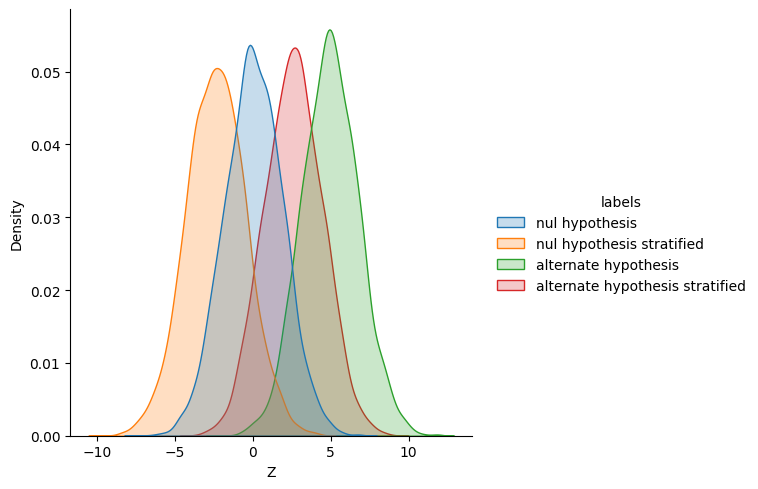

In [60]:
sns_plot = sns.displot(dis, x="Z", hue='labels',kind="kde",fill=True)
plt.show()